# Salary prediction for young developers (multivariate linear regression)
Mission link, use case and dataset

This model could be used by young developers, recent graduates, career advisers, and technology-training programmes to get a rough estimate of the annual salary associated with a developer's experience, skills, job role, and country. It could support career planning, salary discussions, and programme evaluation by helping people understand how different factors relate to pay. This connects to my mission of improving access to meaningful employment and skills development: better information can help young people make informed career decisions, although the prediction is an estimate and not a promise of what an individual will earn.

The data comes from the Stack Overflow 2024 Developer Survey (https://github.com/StackExchange/Survey/blob/main/packages/archive/2024/results.csv). The original public survey file I used here contains 65,437 responses and 114 columns, covering developers backgrounds, locations, work arrangements, experience, technologies, and compensation. The target for this project is ConvertedCompYearly, which represents reported yearly compensation converted to US dollars. The model uses a cleaned subset of 12,848 rows and selected features from the survey, the survey is self-reported, so answers and salary conversions may contain inconsistencies. Dataset and survey information: Stack Overflow Developer Survey.

## 1. Setup

In [1]:
import json
import os

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)

print("scikit-learn version:", sklearn.__version__)  # To ensure I use the SAME version in pyproject.toml so the .pkl loads on Render

scikit-learn version: 1.6.1


### Decisions and settings

In [2]:
RANDOM_STATE = 42
DATA_PATH = "results.csv"          # Stack Overflow 2024 Developer Survey, survey_results_public.csv renamed
MODEL_PATH = "best_model.pkl"      # later copy this file into summative/API/

TARGET = "ConvertedCompYearly"

# Row filters (evidence for each is in section 4)
SALARY_FLOOR = 3000
SALARY_CEIL = 500000
KEEP_AGES = ["18-24 years old", "25-34 years old"]
MAX_YEARS_PRO = 15

# Country grouping (section 5)
MIN_COUNT = 50
ALWAYS_KEEP = ["South Africa", "Nigeria", "Egypt", "Kenya"]
AFRICAN = ["South Africa", "Nigeria", "Egypt", "Kenya", "Ghana", "Morocco", "Ethiopia",
           "Uganda", "United Republic of Tanzania", "Algeria", "Tunisia", "Zimbabwe",
           "Rwanda", "Cameroon", "Senegal", "Zambia", "Sudan", "Mauritius", "Botswana",
           "Namibia", "Cote d'Ivoire", "Malawi", "Mozambique", "Angola"]

# Candidate features (the final list is chosen in section 7)
ALL_NUM = ["YearsCodePro", "YearsCode", "NumLanguages", "NumDatabases", "NumTools"]
ALL_CAT = ["EdLevel", "DevType", "Country", "RemoteWork", "OrgSize", "Age"]
RAW_CANDIDATES = ["YearsCodePro", "YearsCode", "WorkExp", "EdLevel", "DevType", "Country",
                  "RemoteWork", "OrgSize", "Age", "LanguageHaveWorkedWith",
                  "DatabaseHaveWorkedWith", "ToolsTechHaveWorkedWith"]

## 2. Load the data

In [3]:
raw_df = pd.read_csv(DATA_PATH)
print("Rows, columns:", raw_df.shape)
raw_df[["Age", "Country", "EdLevel", "DevType", "YearsCodePro", "OrgSize", TARGET]].head()

Rows, columns: (65437, 114)


,Age,Country,EdLevel,DevType,YearsCodePro,OrgSize,ConvertedCompYearly
0,Under 18 years old,United States of America,Primary/elementary school,NaN,NaN,NaN,NaN
1,35-44 years old,United Kingdom of Great Britain and Northern I...,"Bachelor’s degree (B.A., B.S., B.Eng., etc.)","Developer, full-stack",17,NaN,NaN
2,45-54 years old,United Kingdom of Great Britain and Northern I...,"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",Developer Experience,27,NaN,NaN
3,18-24 years old,Canada,Some college/university study without earning ...,"Developer, full-stack",NaN,NaN,NaN
4,18-24 years old,Norway,"Secondary school (e.g. American high school, G...","Developer, full-stack",NaN,NaN,NaN


## 3. Missing data

Share of rows missing the target: 0.642
Rows that report a salary: 23435
EdLevel                    0.0000
Country                    0.0000
Age                        0.0000
RemoteWork                 0.0003
OrgSize                    0.0011
DevType                    0.0014
YearsCode                  0.0020
LanguageHaveWorkedWith     0.0035
YearsCodePro               0.0038
ToolsTechHaveWorkedWith    0.0825
DatabaseHaveWorkedWith     0.1258
WorkExp                    0.3111
dtype: float64


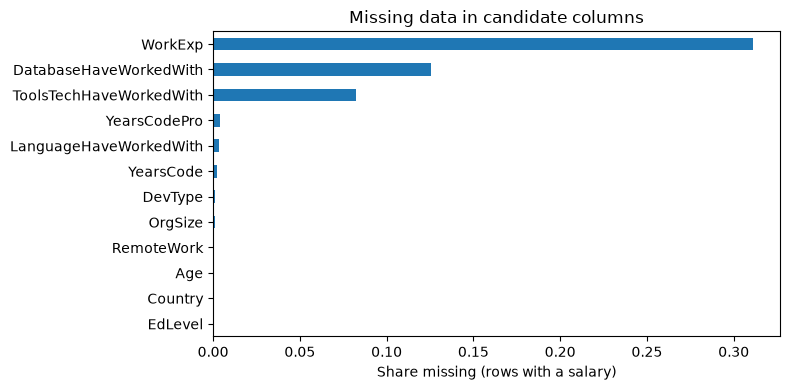

In [4]:
print("Share of rows missing the target:", round(raw_df[TARGET].isna().mean(), 3))

salaried = raw_df[raw_df[TARGET].notna()].copy()
print("Rows that report a salary:", salaried.shape[0])

miss = salaried[RAW_CANDIDATES].isna().mean().sort_values()
print(miss.round(4))

plt.figure(figsize=(8, 4))
miss.plot(kind="barh")
plt.xlabel("Share missing (rows with a salary)")
plt.title("Missing data in candidate columns")
plt.tight_layout()
plt.show()

Since my target from the dataset is the CovertertedCompYearly which is the column that contains the yearly salary of people that filled the survey. From the plot I can see that there are 64.2% of rows that don't have a salary which leaves about 23,435 rows with salaries. Among the rows with salaries core columns like Age, Country, EdLevel, Devtype, YearscodePro, YearsCode, RemoteWork, Orgsize and LanguageHaveWorkedWith all have under 1% missing values but ToolsTechHaveWorkedWith has 8.3% missing values and DatabaseHaveWorkedWith has 12.6% missing values and WorkExp is missing in about 31.1% of rows.

## 4. Target and outliers

Look at the salary distribution first, then gather the evidence for the floor, ceiling and age/experience rules.

count    2.343500e+04
mean     8.615529e+04
std      1.867570e+05
min      1.000000e+00
25%      3.271200e+04
50%      6.500000e+04
75%      1.079715e+05
max      1.625660e+07
Name: ConvertedCompYearly, dtype: float64
0.01       207.68
0.05      3497.00
0.50     65000.00
0.95    210000.00
0.99    393751.06
Name: ConvertedCompYearly, dtype: float64
Below 5000: 1528 | above 500000: 125


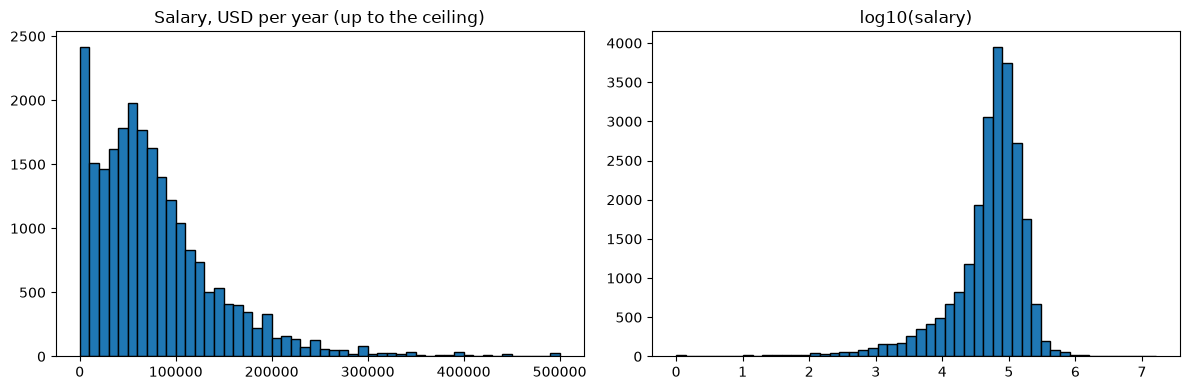

In [5]:
y_raw = salaried[TARGET]
print(y_raw.describe())
print(y_raw.quantile([0.01, 0.05, 0.5, 0.95, 0.99]))
print("Below 5000:", int((y_raw < 5000).sum()), "| above 500000:", int((y_raw > 500000).sum()))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(y_raw[y_raw <= SALARY_CEIL], bins=50, edgecolor="black")
ax[0].set_title("Salary, USD per year (up to the ceiling)")
ax[1].hist(np.log10(y_raw[y_raw > 0]), bins=50, edgecolor="black")
ax[1].set_title("log10(salary)")
plt.tight_layout()
plt.show()

From the plot I can see that the salary distribution is strongly right-skewed and the mean is about $86,155, while the median is $65,000, and reported slaries range from $1 to more than $16 million. That's why I decided to make the log10 plot which makes the distribution easier to see because it compresses the extreme high values, but the model's target is still kept in dollars at this stage. I set a $5,000 floor and a $500,000 ceiling to reduce the influence of unlikely low or unusually high reports while retaining a useful sample, this is a judgement call I made, which means some genuine low or highly paid developers will be excluded.

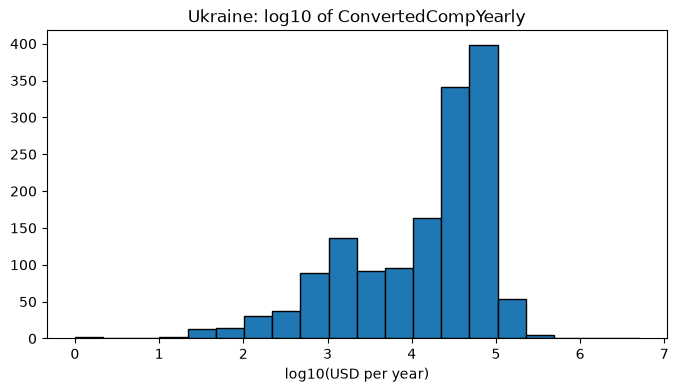

Countries with salaries below 5000:
Country
Ukraine               427
India                 154
Brazil                 58
Pakistan               51
Nigeria                51
Bangladesh             41
Indonesia              39
Russian Federation     38
Turkey                 37
Poland                 26
Name: count, dtype: int64

                       Currency  CompTotal  ConvertedCompYearly
484      UAH\tUkrainian hryvnia     6000.0                148.0
501   USD\tUnited States dollar      650.0                650.0
567      UAH\tUkrainian hryvnia    20000.0                494.0
595      UAH\tUkrainian hryvnia    70500.0               1740.0
602      UAH\tUkrainian hryvnia     6600.0                163.0
696      UAH\tUkrainian hryvnia   200000.0               4937.0
772      UAH\tUkrainian hryvnia     6750.0                167.0
908   USD\tUnited States dollar     1500.0               1500.0
1020     UAH\tUkrainian hryvnia   200000.0               4937.0
1095     UAH\tUkrainian hryvn

In [6]:
ua = salaried[salaried["Country"] == "Ukraine"][TARGET]
plt.figure(figsize=(8, 4))
plt.hist(np.log10(ua[ua > 0]), bins=20, edgecolor="black")
plt.title("Ukraine: log10 of ConvertedCompYearly")
plt.xlabel("log10(USD per year)")
plt.show()

low = salaried[salaried[TARGET] < 5000]
print("Countries with salaries below 5000:")
print(low["Country"].value_counts().head(10))
print()
print(salaried[(salaried["Country"] == "Ukraine") & (salaried[TARGET] < 5000)][["Currency", "CompTotal", TARGET]].head(10))
print()
for floor in [1000, 3000, 5000]:
    n = salaried[TARGET].between(floor, SALARY_CEIL).sum()
    print(f"rows kept with floor {floor}: {n}")

The low-salary records are concentrated especially in Ukraine (427 records below $5,000), followed by India (154), Brazil (58), and Nigeria (51) so I decided to take a closer look at the  Ukraine data which shows that some records report amounts in Ukrainian hryvnia, while others have very small USD amounts, so currency conversion, reporting mistakes, or unusual entries may be mixed together, the data alone cannot prove which individual values are errors. So I chose a $3,000 floor as a compromise, it removes more suspicious very-low values than a $1,000 floor while retaining 22,233 salary records before the other filters, compared with 21,782 at a $5,000 floor, so it avoids excluding as many potentially genuine lower-paid developers.

In [7]:
def years_to_num(s):
    """Experience columns hold numbers as text plus two labels; turn them into numbers."""
    s = s.replace({"Less than 1 year": 0, "More than 50 years": 50})
    return pd.to_numeric(s, errors="coerce")


def count_items(s):
    """Number of semicolon-separated items in a multi-select column; blank counts as 0."""
    return s.fillna("").apply(lambda x: len([i for i in x.split(";") if i.strip()]))


# Evidence for the age and experience rules
chk = salaried[["Age"]].copy()
chk["yp"] = years_to_num(salaried["YearsCodePro"])
print(salaried["Age"].value_counts())
print()
print("Impossible-looking combinations (more than 15 years professional experience by age band):")
print(pd.crosstab(chk["Age"], chk["yp"] > MAX_YEARS_PRO))
print()
print("Rows with YearsCodePro <= 2 / 3 / 5:", [int((chk["yp"] <= c).sum()) for c in (2, 3, 5)])

# Evidence for dropping WorkExp
we = pd.DataFrame({"WorkExp": salaried["WorkExp"], "YearsCodePro": years_to_num(salaried["YearsCodePro"])})
print()
print(we.corr().round(3))
print("WorkExp missing share:", round(salaried["WorkExp"].isna().mean(), 3))

Age
25-34 years old       10369
35-44 years old        6231
18-24 years old        3433
45-54 years old        2329
55-64 years old         863
65 years or older       137
Under 18 years old       64
Prefer not to say         9
Name: count, dtype: int64

Impossible-looking combinations (more than 15 years professional experience by age band):
yp                  False  True 
Age                             
18-24 years old      3431      2
25-34 years old     10300     69
35-44 years old      4126   2105
45-54 years old       438   1891
55-64 years old        73    790
65 years or older       6    131
Prefer not to say       5      4
Under 18 years old     64      0

Rows with YearsCodePro <= 2 / 3 / 5: [3442, 5371, 8683]

              WorkExp  YearsCodePro
WorkExp         1.000         0.926
YearsCodePro    0.926         1.000
WorkExp missing share: 0.311


I kept the 18–24 and 25–34 age bands because the project is intended to inform young developers and people starting or building their careers, which directly supports my mission around youth skills development and access to employment. The 15-year cap on YearsCodePro keeps the analysis focused on junior to intermediate developers and limits cases that do not fit the intended group, the age by experience table also shows that long professional histories are much more common in older age bands. I dropped WorkExp because it is strongly correlated with YearsCodePro (0.926), which means the two variables carry overlapping information, and because WorkExp is missing for 31.1% of salary-reporting respondents.

## 5. Cleaning and country grouping

In [ ]:
work = salaried.copy()
work["YearsCodePro"] = years_to_num(work["YearsCodePro"])
work["YearsCode"] = years_to_num(work["YearsCode"])

# Row filters
work = work[work[TARGET].between(SALARY_FLOOR, SALARY_CEIL)]
work = work[work["Age"].isin(KEEP_AGES)]
work = work[~(work["YearsCodePro"] > MAX_YEARS_PRO)]   # keeps missing values the Pipeline imputes them later

# Count features from the multi-select columns
work["NumLanguages"] = count_items(work["LanguageHaveWorkedWith"])
work["NumDatabases"] = count_items(work["DatabaseHaveWorkedWith"])
work["NumTools"] = count_items(work["ToolsTechHaveWorkedWith"])

data = work[ALL_NUM + ALL_CAT + [TARGET]].reset_index(drop=True)
data["CountryRaw"] = data["Country"]      # original country, kept for the African-rows check

print("Cleaned shape:", data.shape)
print(data.isna().mean().sort_values().round(4))
print(data[TARGET].describe())

Cleaned shape: (12848, 13)
NumDatabases           0.0000
NumLanguages           0.0000
EdLevel                0.0000
NumTools               0.0000
Country                0.0000
CountryRaw             0.0000
Age                    0.0000
ConvertedCompYearly    0.0000
RemoteWork             0.0002
DevType                0.0012
OrgSize                0.0015
YearsCode              0.0019
YearsCodePro           0.0040
dtype: float64
count     12848.000000
mean      66496.000700
std       56840.486084
min        3000.000000
25%       27079.750000
50%       53703.000000
75%       87446.750000
max      500000.000000
Name: ConvertedCompYearly, dtype: float64


In [9]:
counts = data["CountryRaw"].value_counts()
keep_countries = sorted(set(counts[counts >= MIN_COUNT].index) | {c for c in ALWAYS_KEEP if c in counts.index})
data["Country"] = data["CountryRaw"].where(data["CountryRaw"].isin(keep_countries), "Other")

print(len(keep_countries), "countries kept;", int((data["Country"] == "Other").sum()), "of", len(data), "rows grouped as Other")

other_summary = (data[data["Country"] == "Other"].groupby("CountryRaw")[TARGET].agg(["count", "median"]))
print(other_summary[other_summary["count"] >= 30].sort_values("count", ascending=False).head(15))

with open("keep_countries.json", "w") as f:    # the API needs this list
    json.dump(keep_countries, f)

48 countries kept; 1070 of 12848 rows grouped as Other
                      count   median
CountryRaw                          
Slovenia                 46  48333.0
Croatia                  45  45111.0
Serbia                   45  36884.0
Philippines              44  16953.5
Hong Kong (S.A.R.)       40  45438.0
Sri Lanka                37  11852.0
Singapore                35  88699.0
Estonia                  33  59073.0
United Arab Emirates     33  57175.0
South Korea              32  38804.5
Malaysia                 31  15256.0
Thailand                 30  31061.5


I kept countries with at least 50 observations so that the model has enough examples to learn a country-level pattern, while deliberately retaining South Africa, Nigeria, Egypt, and Kenya even if they do not meet that threshold because they are important to the African focus of this project. This leaves 48 named countries and groups 1,070 rows into Other. That group is convenient for less-represented countries, but it hides substantial differences in pay, for example, the median salaries shown for countries in Other range from around $11,852 in Sri Lanka to $88,699 in Singapore, so Other should not be interpreted as one economically similar country. Keeping the selected African countries separate makes their patterns visible rather than automatically combining them with countries from very different regions.

## 6. Exploratory plots

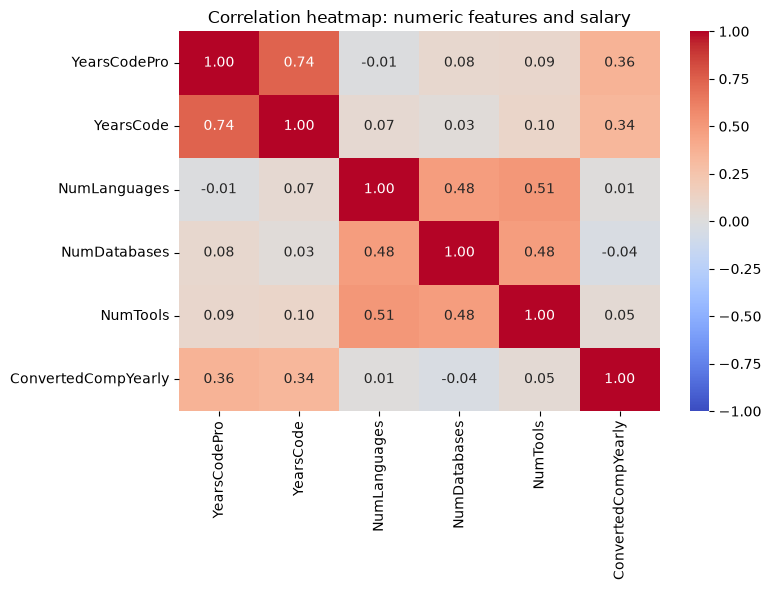

YearsCodePro    0.363
YearsCode       0.339
NumTools        0.053
NumDatabases    0.037
NumLanguages    0.014
Name: ConvertedCompYearly, dtype: float64
Feature most correlated with the target: YearsCodePro


In [10]:
corr = data[ALL_NUM + [TARGET]].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation heatmap: numeric features and salary")
plt.tight_layout()
plt.show()

corr_ranking = corr[TARGET].drop(TARGET).abs().sort_values(ascending=False)
print(corr_ranking.round(3))
TOP_FEATURE = corr_ranking.index[0]
print("Feature most correlated with the target:", TOP_FEATURE)

The heatmap shows that professional coding experience (YearsCodePro, correlation 0.363) and total coding experience (YearsCode, 0.339) have the clearest positive relationships with yearly salary, although these are moderate rather than strong correlations. The counts of tools (0.053), databases (0.037), and languages (0.014) have very weak individual relationships with salary, so technology counts alone do not explain much of the variation. I kept the experience measures and initially retain the counts for feature evaluation, but I treated YearsCode and YearsCodePro as partly overlapping measures rather than independent explanations, the later permutation importance results I got helped me decide which features add useful predictive information.

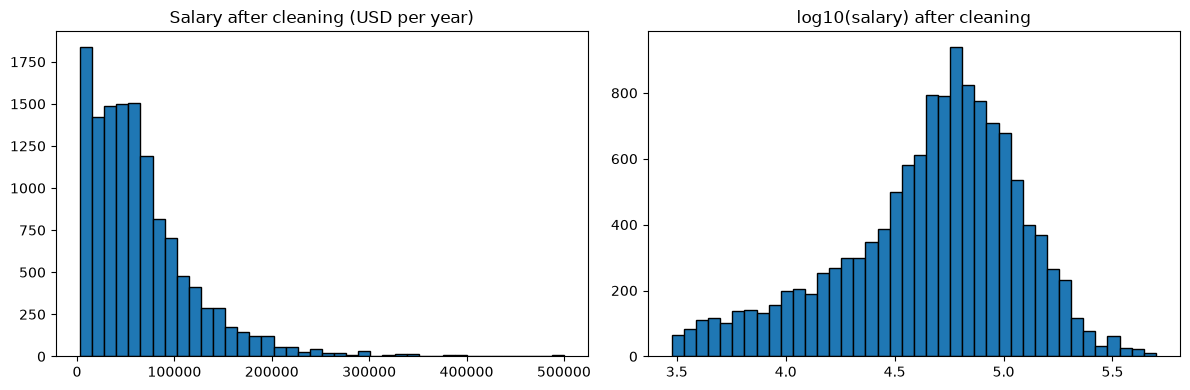

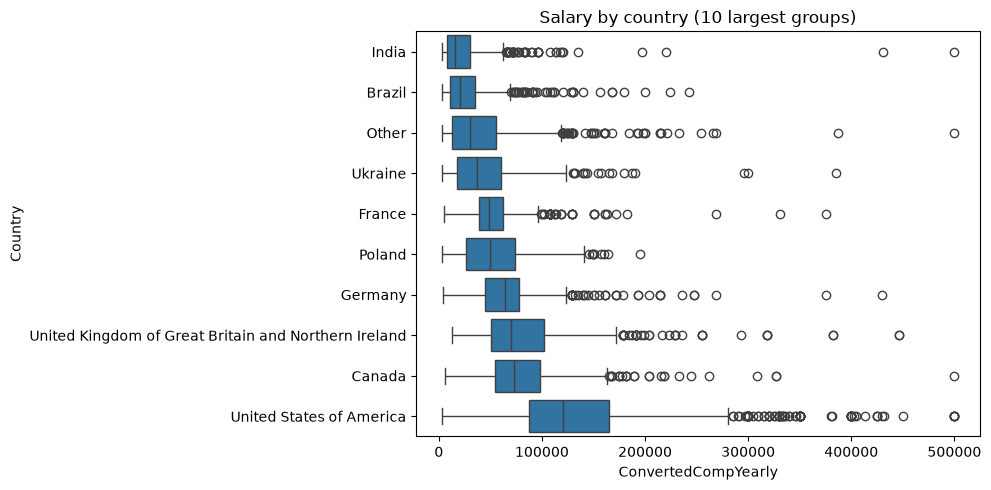

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(data[TARGET], bins=40, edgecolor="black")
ax[0].set_title("Salary after cleaning (USD per year)")
ax[1].hist(np.log10(data[TARGET]), bins=40, edgecolor="black")
ax[1].set_title("log10(salary) after cleaning")
plt.tight_layout()
plt.show()

top10 = data["Country"].value_counts().head(10).index
sub = data[data["Country"].isin(top10)]
order = sub.groupby("Country")[TARGET].median().sort_values().index
plt.figure(figsize=(10, 5))
sns.boxplot(data=sub, x=TARGET, y="Country", order=order)
plt.title("Salary by country (10 largest groups)")
plt.tight_layout()
plt.show()

The salary after cleaning histogram has a long right tail, with most observations at lower salary levels and a smaller number of much higher salaries, the log10 histogram is more balanced and makes the main concentration easier to see. The country boxplot shows clear differences between country salary distributions, the United States has a much higher median and wider spread than countries such as India and Brazil, while there are many high-salary outliers across several countries. This supports keeping country as an important categorical feature and confirms that the $500,000 ceiling reduces the most extreme values without removing all variation within each country.

## 7. Train/test split, feature importance and final features

One split is made on all candidate features. Importance is measured on a validation slice of the **training** data only, so the test set is never used to choose features.

Country         0.6888
YearsCodePro    0.1558
OrgSize         0.0374
DevType         0.0358
YearsCode       0.0160
EdLevel         0.0137
NumLanguages    0.0101
RemoteWork      0.0066
Age             0.0053
NumTools        0.0037
NumDatabases    0.0032
dtype: float64


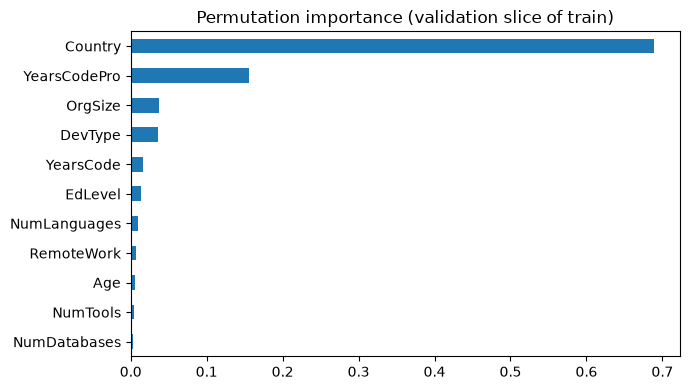

In [12]:
def make_preprocess(num_features, cat_features):
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                          ("scale", StandardScaler())]), num_features),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="Unknown")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore"))]), cat_features),
    ])


X_all = data[ALL_NUM + ALL_CAT]
y = data[TARGET]
X_train_all, X_test_all, y_train, y_test = train_test_split(X_all, y, test_size=0.2, random_state=RANDOM_STATE)

X_tr, X_val, y_tr, y_val = train_test_split(X_train_all, y_train, test_size=0.2, random_state=RANDOM_STATE)
rf_importance = Pipeline([("prep", make_preprocess(ALL_NUM, ALL_CAT)),
                          ("model", RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1))])
rf_importance.fit(X_tr, y_tr)
perm = permutation_importance(rf_importance, X_val, y_val, n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=X_val.columns).sort_values(ascending=False)
print(importance.round(4))

importance.sort_values().plot(kind="barh", figsize=(7, 4), title="Permutation importance (validation slice of train)")
plt.tight_layout()
plt.show()

The permutation importance  identifies Country as the strongest feature by a wide margin (0.6888), followed by YearsCodePro (0.1558), OrgSize and DevType contribute smaller amounts, while the remaining features have relatively low importance. I removed Age because the selected dataset has already been restricted to the two young age bands, so it offers little additional distinction, and I removed NumDatabases and NumTools because their importance scores are very small (0.0032 and 0.0037). I retained YearsCode, NumLanguages, education, role, remote-work arrangement, and organisation size as additional context, resulting in eight raw input features, importance indicates predictive usefulness in this dataset, not that a feature causes higher pay.

In [13]:
NUM_FEATURES = ["YearsCodePro", "YearsCode", "NumLanguages"]
CAT_FEATURES = ["EdLevel", "DevType", "Country", "RemoteWork", "OrgSize"]
FEATURES = NUM_FEATURES + CAT_FEATURES
assert len(FEATURES) >= 8, "The brief needs at least 8 feature columns"

X_train = X_train_all[FEATURES]
X_test = X_test_all[FEATURES]

preprocess = make_preprocess(NUM_FEATURES, CAT_FEATURES)
Xtr = preprocess.fit_transform(X_train)      # fit on TRAIN only
Xte = preprocess.transform(X_test)

# Target in thousands of USD keeps SGD numerically stable; the API multiplies predictions by 1000
y_train_k = y_train / 1000
y_test_k = y_test / 1000

print("Final features:", FEATURES)
print("Train/test shapes (raw):", X_train.shape, X_test.shape)
print("Train/test shapes (encoded):", Xtr.shape, Xte.shape)
print("Target variance train / test (k USD squared):", round(y_train_k.var(), 1), "/", round(y_test_k.var(), 1))

Final features: ['YearsCodePro', 'YearsCode', 'NumLanguages', 'EdLevel', 'DevType', 'Country', 'RemoteWork', 'OrgSize']
Train/test shapes (raw): (10278, 8) (2570, 8)
Train/test shapes (encoded): (10278, 110) (2570, 110)
Target variance train / test (k USD squared): 3269.2 / 3078.2


## 8. Tune SGDRegressor

Tuning uses a validation slice of the training data. The test set is not touched.

In [14]:
Xa, Xv, ya, yv = train_test_split(Xtr, y_train_k, test_size=0.2, random_state=RANDOM_STATE)


def sgd_curve(eta0, alpha, epochs, X_fit, y_fit, X_eval, y_eval):
    """Train with partial_fit and record MSE on both sets after every epoch."""
    sgd = SGDRegressor(learning_rate="constant", eta0=eta0, penalty="l2", alpha=alpha, random_state=RANDOM_STATE)
    fit_losses, eval_losses = [], []
    for _ in range(epochs):
        sgd.partial_fit(X_fit, y_fit)
        fit_losses.append(mean_squared_error(y_fit, sgd.predict(X_fit)))
        eval_losses.append(mean_squared_error(y_eval, sgd.predict(X_eval)))
    return sgd, fit_losses, eval_losses


etas = [0.0001, 0.0005, 0.001, 0.005, 0.01]
alphas = [1e-6, 1e-5, 1e-3, 1e-1]
epoch_options = [50, 100, 200, 400]

rows = []
for eta0 in etas:
    for alpha in alphas:
        _, _, ev = sgd_curve(eta0, alpha, max(epoch_options), Xa, ya, Xv, yv)
        for ep in epoch_options:
            rows.append({"eta0": eta0, "alpha": alpha, "epochs": ep, "val_MSE": ev[ep - 1]})
tuning = pd.DataFrame(rows).sort_values("val_MSE").reset_index(drop=True)
print(tuning.head(10))

best_row = tuning.iloc[0]
BEST_ETA, BEST_ALPHA, BEST_EPOCHS = float(best_row["eta0"]), float(best_row["alpha"]), int(best_row["epochs"])
print("Chosen:", BEST_ETA, BEST_ALPHA, BEST_EPOCHS)

     eta0     alpha  epochs      val_MSE
0  0.0005  0.000001     200  1493.376678
1  0.0005  0.000010     200  1493.389272
2  0.0010  0.000001     100  1493.402249
3  0.0010  0.000010     100  1493.414391
4  0.0005  0.000010     400  1493.883987
5  0.0005  0.000001     400  1493.887319
6  0.0010  0.000010     200  1493.917297
7  0.0010  0.000001     200  1493.921110
8  0.0010  0.000010     400  1493.940610
9  0.0010  0.000001     400  1493.946690
Chosen: 0.0005 1e-06 200


eta0
0.0001    1497.6
0.0005    1493.4
0.0010    1493.4
0.0050    1529.6
0.0100    1602.6

alpha
0.000001    1493.4
0.000010    1493.4
0.001000    1497.4
0.100000    1911.6

epochs
50     1494.6
100    1493.4
200    1493.4
400    1493.9

LinearRegression validation MSE: 1495.1 | best SGD: 1493.4


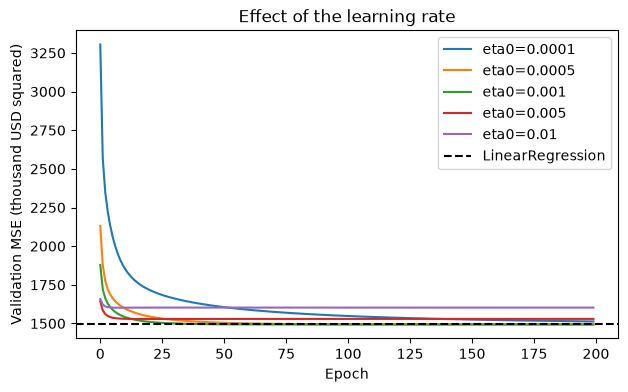

In [ ]:
# How much did each hyperparameter change the loss
for col in ["eta0", "alpha", "epochs"]:
    print(tuning.groupby(col)["val_MSE"].min().round(1).to_string())
    print()

lin_val = LinearRegression().fit(Xa, ya)
lin_val_mse = mean_squared_error(yv, lin_val.predict(Xv))
print("LinearRegression validation MSE:", round(lin_val_mse, 1), "| best SGD:", round(best_row["val_MSE"], 1))

plt.figure(figsize=(7, 4))
for eta in etas:
    _, _, ev = sgd_curve(eta, BEST_ALPHA, 200, Xa, ya, Xv, yv)
    plt.plot(ev, label=f"eta0={eta}")
plt.axhline(lin_val_mse, ls="--", color="k", label="LinearRegression")
plt.xlabel("Epoch")
plt.ylabel("Validation MSE (thousand USD squared)")
plt.title("Effect of the learning rate")
plt.legend()
plt.show()

I tuned the SGD learning rate (eta0), L2 regularisation strength (alpha), and number of epochs, selecting the combination with the lowest validation MSE. A learning rate of 0.0005 gave a low loss, while larger rates such as 0.005 and 0.01 performed worse, stronger regularisation also increased the loss, especially at alpha=0.1, and performance improved from 50 to about 100–200 epochs before 400 epochs gave little to no benefit. The best SGD validation MSE was about 1493.4 (thousand-USD squared), slightly below the validation LinearRegression result of 1495.1, so SGD can reach a comparable result when tuned, although the difference is very small.

## 9. Four models and the comparison table

In [16]:
sgd_best, train_curve, test_curve = sgd_curve(BEST_ETA, BEST_ALPHA, BEST_EPOCHS, Xtr, y_train_k, Xte, y_test_k)

lin = LinearRegression().fit(Xtr, y_train_k)
tree = DecisionTreeRegressor(max_depth=10, min_samples_leaf=20, random_state=RANDOM_STATE).fit(Xtr, y_train_k)
forest = RandomForestRegressor(n_estimators=200, max_depth=15, min_samples_leaf=5,
                               random_state=RANDOM_STATE, n_jobs=-1).fit(Xtr, y_train_k)

models = {"SGDRegressor": sgd_best, "LinearRegression": lin, "DecisionTree": tree, "RandomForest": forest}

rows = []
for name, m in models.items():
    p_tr, p_te = m.predict(Xtr), m.predict(Xte)
    rows.append({"model": name,
                 "train_MSE": mean_squared_error(y_train_k, p_tr),
                 "test_MSE": mean_squared_error(y_test_k, p_te),
                 "test_RMSE_kUSD": mean_squared_error(y_test_k, p_te) ** 0.5,
                 "test_R2": r2_score(y_test_k, p_te)})
results = pd.DataFrame(rows).sort_values("test_MSE").reset_index(drop=True)
print(results.round(3).to_string(index=False))

baseline_mse = mean_squared_error(y_test_k, np.full(len(y_test_k), y_train_k.mean()))
best_name = results.loc[0, "model"]
print()
print("Predict-the-mean baseline test MSE:", round(baseline_mse, 1))
print("BEST MODEL (lowest test MSE):", best_name)

           model  train_MSE  test_MSE  test_RMSE_kUSD  test_R2
LinearRegression   1510.910  1405.508          37.490    0.543
    SGDRegressor   1511.850  1407.631          37.518    0.543
    RandomForest   1129.653  1476.402          38.424    0.520
    DecisionTree   1542.914  1646.274          40.574    0.465

Predict-the-mean baseline test MSE: 3077.6
BEST MODEL (lowest test MSE): LinearRegression


In [ ]:
cands = {
    "LinearRegression": LinearRegression(),
    "RandomForest": RandomForestRegressor(n_estimators=200, max_depth=15, min_samples_leaf=5,
                                          random_state=RANDOM_STATE, n_jobs=-1),
    "DecisionTree": DecisionTreeRegressor(max_depth=10, min_samples_leaf=20, random_state=RANDOM_STATE),
}
for name, m in cands.items():
    pipe = Pipeline([("prep", make_preprocess(NUM_FEATURES, CAT_FEATURES)), ("model", m)])
    s = -cross_val_score(pipe, X_train, y_train_k, cv=5, scoring="neg_mean_squared_error")
    print(f"{name}: CV MSE {s.mean():.1f} +/- {s.std():.1f}")

LinearRegression: CV MSE 1543.7 +/- 187.8
RandomForest: CV MSE 1574.7 +/- 170.5
DecisionTree: CV MSE 1760.2 +/- 166.3


Best model: LinearRegression. I selected it because it has the lowest test MSE (1405.508), narrowly ahead of SGDRegressor (1407.631), and it also has the strongest test R² tie at 0.543, the five-fold training cross-validation results show that they’re statistically close and so I went with lowest test MSE in accordance with the assignment prompt, with a mean MSE of 1543.7 compared with 1574.7 for RandomForest. A linear model is a reasonable baseline here because salary appears to reflect a broad country-level difference plus an experience effect, even though real salaries are more complex than a straight-line relationship. The RandomForest has a much lower training MSE (1129.653) than test MSE (1476.402), which is evidence of overfitting, the DecisionTree performs worst on the test set (1646.274), while SGD is almost tied with LinearRegression. The very strong country signal, one-hot encoded categorical variables, remaining salary variation and outliers all affect the results, so the model captures useful broad patterns but cannot explain every individual's pay.

## 10. Required plots

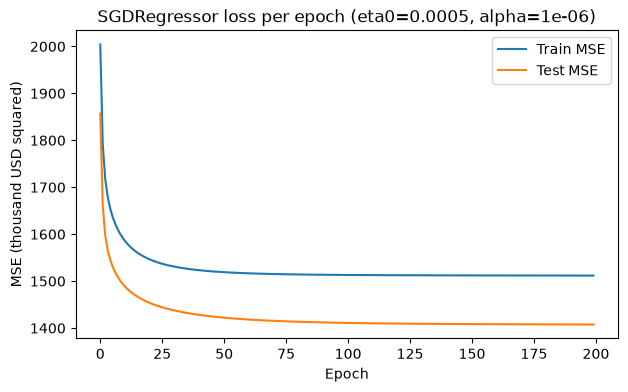

In [18]:
# Loss curve: train and test MSE per epoch for SGDRegressor
plt.figure(figsize=(7, 4))
plt.plot(train_curve, label="Train MSE")
plt.plot(test_curve, label="Test MSE")
plt.xlabel("Epoch")
plt.ylabel("MSE (thousand USD squared)")
plt.title(f"SGDRegressor loss per epoch (eta0={BEST_ETA}, alpha={BEST_ALPHA})")
plt.legend()
plt.show()

The training and test losses both fall sharply during the early epochs and then flatten, showing that SGD learns most of what it can very quickly by around 100–200 epochs, additional training produces only small improvements. The test curve stays below the training curve rather than diverging, which does not automatically mean the model performs better on unseen data, the particular test split may simply be somewhat easier, and the curves are calculated on different samples. So I kept the tuned 200-epoch setting and relied on the separate model comparison and cross-validation, rather than interpreting the lower test curve as proof of generalisation.

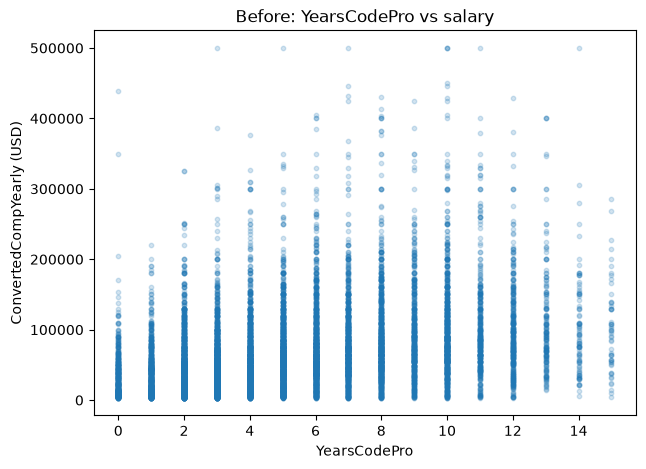

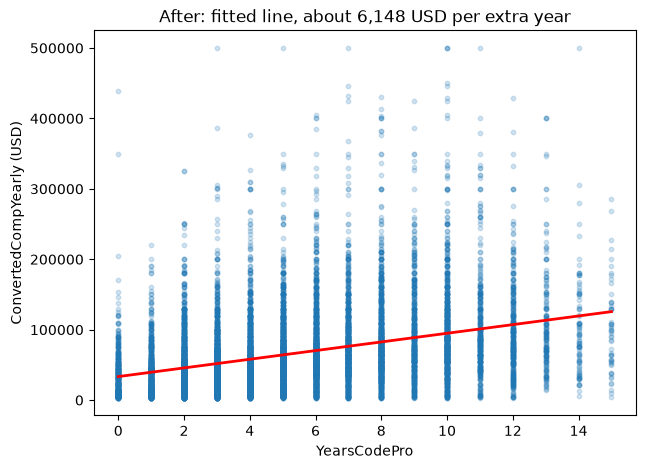

In [19]:
d = data[[TOP_FEATURE, TARGET]].dropna()

# Scatter, before
plt.figure(figsize=(7, 5))
plt.scatter(d[TOP_FEATURE], d[TARGET], alpha=0.2, s=10)
plt.xlabel(TOP_FEATURE)
plt.ylabel(TARGET + " (USD)")
plt.title(f"Before: {TOP_FEATURE} vs salary")
plt.show()

# Scatter, after: one-feature linear regression, used for this plot only
line = LinearRegression().fit(d[[TOP_FEATURE]], d[TARGET])
xs = pd.DataFrame({TOP_FEATURE: np.linspace(d[TOP_FEATURE].min(), d[TOP_FEATURE].max(), 100)})
plt.figure(figsize=(7, 5))
plt.scatter(d[TOP_FEATURE], d[TARGET], alpha=0.2, s=10)
plt.plot(xs[TOP_FEATURE], line.predict(xs), color="red", linewidth=2)
plt.xlabel(TOP_FEATURE)
plt.ylabel(TARGET + " (USD)")
plt.title(f"After: fitted line, about {line.coef_[0]:,.0f} USD per extra year")
plt.show()

The scatter plot shows a positive relationship between YearsCodePro and salary, and the fitted line has a slope of about $6,148 per additional professional coding year in this one-feature analysis. However, the points are widely spread around the line at almost every experience level, and high and low salaries occur for developers with similar experience, the relationship is therefore not precise enough to predict salary by experience alone. This is why the final model uses multiple features, especially country, alongside experience and work/education characteristics.

## 11. Save the best model and predict one row

In [20]:
best_model = models[best_name]
best_pipe = Pipeline([("prep", preprocess), ("model", best_model)])   # preprocessing and model saved together
# Keep the cleaned training rows inside the saved file: /retrain needs them to refit on old + new data
best_pipe.training_data_ = data[FEATURES + [TARGET]].reset_index(drop=True)
joblib.dump(best_pipe, MODEL_PATH)

size_mb = os.path.getsize(MODEL_PATH) / 1e6
print(f"Saved {MODEL_PATH} ({size_mb:.2f} MB) with scikit-learn {sklearn.__version__}")

# Sanity check: the reloaded pipeline matches the model's own predictions
reloaded = joblib.load(MODEL_PATH)
print("Reloaded predictions match:", np.allclose(reloaded.predict(X_test), best_model.predict(Xte)))


def predict_one_row(model_path, X_df, y_series, row_index=0):
    """Load the saved pipeline and predict the salary (USD) for one row of the test set."""
    pipe = joblib.load(model_path)
    row = X_df.iloc[[row_index]]
    predicted_usd = pipe.predict(row)[0] * 1000     # the model works in thousands of USD
    return predicted_usd, y_series.iloc[row_index]


pred, actual = predict_one_row(MODEL_PATH, X_test, y_test, 0)
print(f"Row 0 of the test set -> predicted ${pred:,.0f}, actual ${actual:,.0f}")

Saved best_model.pkl (0.59 MB) with scikit-learn 1.6.1
Reloaded predictions match: True
Row 0 of the test set -> predicted $56,929, actual $47,557


## 12. How the model does on African developers

In [21]:
raw_country_test = data.loc[X_test.index, "CountryRaw"]
mask = raw_country_test.isin(AFRICAN).to_numpy()
pred_k = best_pipe.predict(X_test)

print("African rows in the test set:", int(mask.sum()))
if mask.sum() > 0:
    rmse_af = mean_squared_error(y_test_k.to_numpy()[mask], pred_k[mask]) ** 0.5
    rmse_all = mean_squared_error(y_test_k, pred_k) ** 0.5
    print(f"RMSE on African rows: {rmse_af:.1f}k USD | on all test rows: {rmse_all:.1f}k USD")
    print("(only a few dozen rows, so this is indicative, not conclusive)")

African rows in the test set: 53
RMSE on African rows: 24.9k USD | on all test rows: 37.5k USD
(only a few dozen rows, so this is indicative, not conclusive)


The overall test RMSE is about $37.5k, which is substantial for an individual salary estimate because a prediction can be tens of thousands of dollars away from the reported value. The African subset has an RMSE of $24.9k, lower than the overall test RMSE, but it contains only 53 rows, so this small sample is only indicative and does not prove that the model is reliably accurate for African developers or for every African country. To improve it, I would test a log-transformed salary target to reduce the influence of high salaries, explore country-by-experience interactions, add more survey years to increase African representation, and use specific technologies and skills rather than only counts of languages, tools, and databases.

## 13. Facts the API needs

In [24]:
api_schema = {
    "target_unit": "model predicts thousands of USD per year; multiply by 1000",
    "best_model": best_name,
    "num_ranges": {c: [float(data[c].min()), float(data[c].max())] for c in NUM_FEATURES},
    "categories": {c: sorted(data[c].dropna().unique().tolist()) for c in CAT_FEATURES},
    "feature_order": FEATURES,
    "sklearn_version": sklearn.__version__,
}
with open("api_schema.json", "w") as f:
    json.dump(api_schema, f, indent=2)

print("Numeric ranges (use these for the Pydantic Field(ge=, le=) limits):")
for c, r in api_schema["num_ranges"].items():
    print(" ", c, r)
for c, vals in api_schema["categories"].items():
    print(f"{c}: {len(vals)} values")
print()

Numeric ranges (use these for the Pydantic Field(ge=, le=) limits):
  YearsCodePro [0.0, 15.0]
  YearsCode [0.0, 34.0]
  NumLanguages [0.0, 32.0]
EdLevel: 8 values
DevType: 34 values
Country: 49 values
RemoteWork: 3 values
OrgSize: 10 values



I added the keep_countries.json and api_schema.json files so I can have a list of allowed variables for the API 

In [23]:
data[FEATURES + [TARGET]].head(100).to_csv("retrain_test.csv", index=False)

I added this cell so I can create a subset dataset to be able to test the retrain endpoint of the API.